# Иерархический кластерный анализ

#### Econom_Cities_data

## Библиотечки

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

## Загрузка

In [2]:
df = pd.read_csv(
    "Econom_Cities_data (1).csv",
    sep=";",
    decimal=",",
    na_values=-9999,
)

In [3]:
df.shape

(48, 4)

In [4]:
df.head()

,City,Work,Price,Salary
0,Amsterdam,1714.0,65.6,49.0
1,Athens,1792.0,53.8,30.4
2,Bogota,2152.0,37.9,11.5
3,Bombay,2052.0,30.3,5.3
4,Brussels,1708.0,73.8,50.5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     str    
 1   Work    46 non-null     float64
 2   Price   48 non-null     float64
 3   Salary  46 non-null     float64
dtypes: float64(3), str(1)
memory usage: 2.0 KB


In [6]:
df[df.isna().any(axis=1)]

,City,Work,Price,Salary
6,Cairo,NaN,37.1,NaN
17,Jakarta,NaN,43.6,NaN


Решила их дропнуть, вместо заполнения средним или медианой

In [7]:
features = ["Work", "Price", "Salary"]

data = df.dropna().copy()
data.shape

(46, 4)

## Мини анализ

In [8]:
data[features].describe().round(2)

,Work,Price,Salary
count,46.00,46.00,46.00
mean,1879.91,70.10,39.55
std,174.34,21.39,24.76
min,1583.00,30.30,2.70
25%,1745.25,51.78,14.38
50%,1849.00,70.95,43.65
75%,1976.25,81.90,59.70
max,2375.00,115.50,100.00


In [9]:
for column in features:
    min_row = data.loc[data[column].idxmin()]
    max_row = data.loc[data[column].idxmax()]

    print(column)
    print("Минимум:", min_row["City"], min_row[column])
    print("Максимум:", max_row["City"], max_row[column])

Work
Минимум: Oslo 1583.0
Максимум: Hong_Kong 2375.0
Price
Минимум: Bombay 30.3
Максимум: Oslo 115.5
Salary
Минимум: Lagos 2.7
Максимум: Zurich 100.0


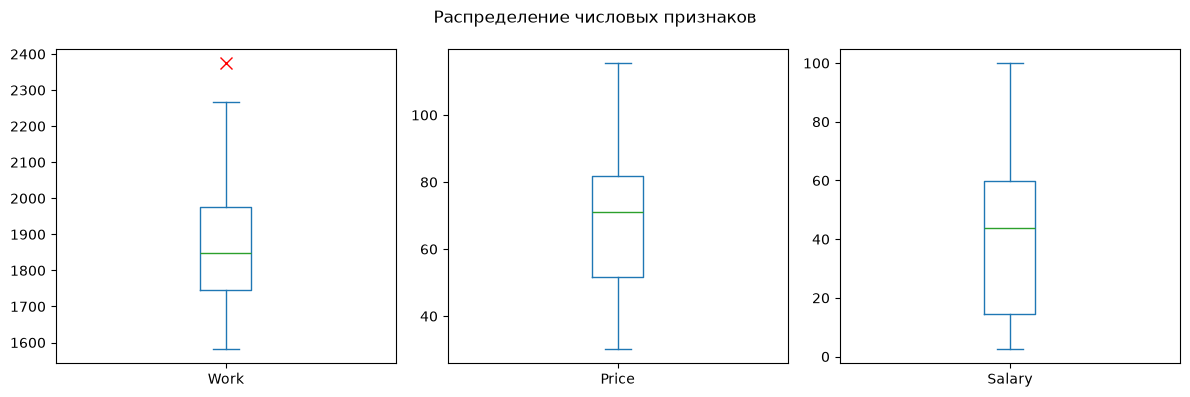

In [10]:
data[features].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 4),
    sharey=False,
    flierprops={"marker": "x", "markeredgecolor": "red", "markersize": 8},
)

plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

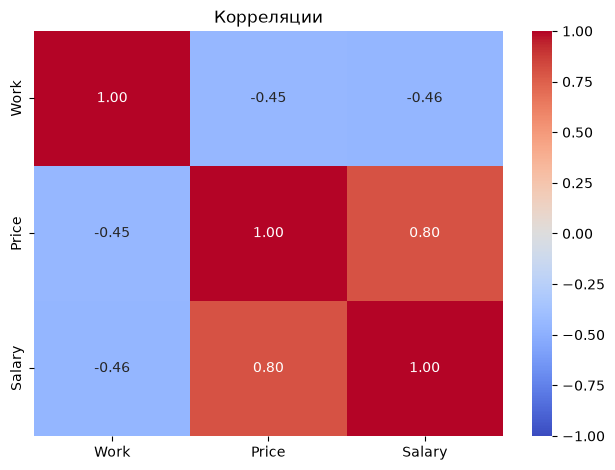

In [11]:
sns.heatmap(
    data[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Корреляции")
plt.tight_layout()
plt.show()

Самая сильная связь между price и salary

## Стандартизация

`Work` измеряется тысячами часов, а индексы `Price` и `Salary` - десятками (чтобы они не влияли на евклидово пространство)

In [12]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data[features])

## Построение иерархии

метод Уорда (объедиение групп так, чтобы максимально увеличить внутрикластерную сумму квадратов) и евклидово расстояние

In [13]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

In [14]:
def plot_dendrogram(linkage_matrix, labels, cut_height=None, figsize=(15, 7)):
    plt.figure(figsize=figsize)
    dendrogram(
        linkage_matrix,
        labels=labels,
        leaf_rotation=90,
        leaf_font_size=8,
        color_threshold=cut_height,
        above_threshold_color="gray",
    )

    if cut_height is not None:
        plt.axhline(
            cut_height,
            color="red",
            linestyle="--",
            label=f"Линия среза = {cut_height:.2f}",
        )
        plt.legend()

    plt.title("Дендрограмма: метод Уорда")
    plt.xlabel("Города")
    plt.ylabel("Расстояние объединения")
    plt.tight_layout()
    plt.show()

In [15]:
distances = Z[:, 2]
jumps = np.diff(distances)
jump_index = jumps.argmax()

cut_height = (distances[jump_index] + distances[jump_index + 1]) / 2
suggested_k = len(data) - jump_index - 1

print("Число кластеров:", suggested_k)

Число кластеров: 2


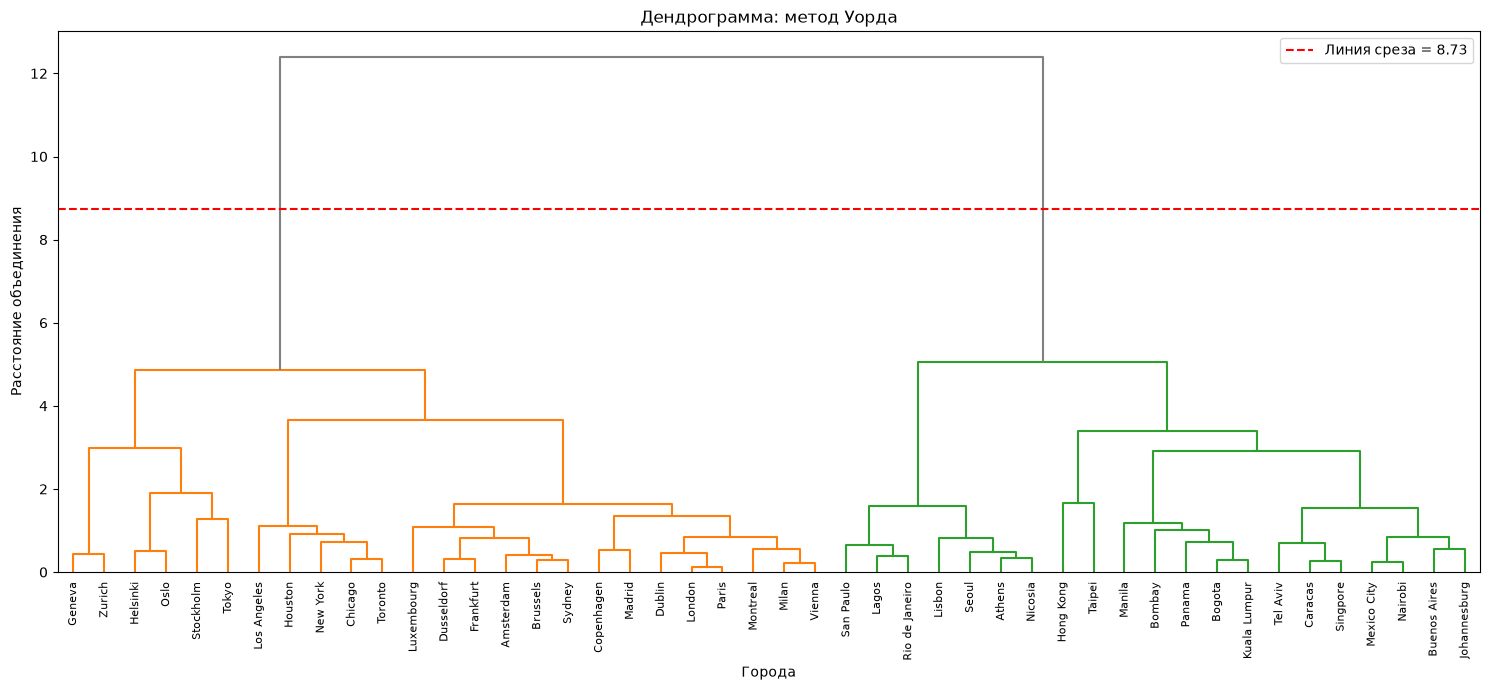

In [16]:
city_labels = data["City"].str.replace("_", " ", regex=False).tolist()
plot_dendrogram(Z, city_labels, cut_height)

## Проверка числа кластеров

Посмотрим от 2 до 10 (не хочу брать больше, так как у нас всего 46 объектов)

In [17]:
def get_silhouette_scores(X, linkage_matrix, k_values):
    scores = []

    for k in k_values:
        labels = fcluster(linkage_matrix, t=k, criterion="maxclust")
        scores.append(silhouette_score(X, labels))

    return scores

In [18]:
k_values = list(range(2, 11))
silhouette_scores = get_silhouette_scores(X_scaled, Z, k_values)
best_k = k_values[np.argmax(silhouette_scores)]

best_k

2

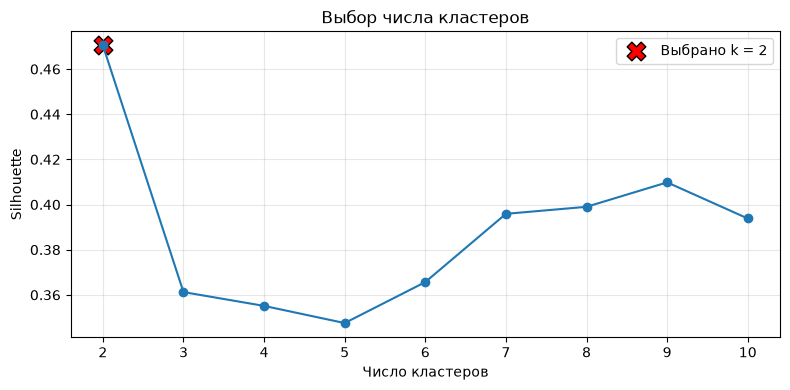

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, silhouette_scores, marker="o")
plt.scatter(
    best_k,
    max(silhouette_scores),
    marker="X",
    s=180,
    color="red",
    edgecolor="black",
    label=f"Выбрано k = {best_k}",
)
plt.xlabel("Число кластеров")
plt.ylabel("Silhouette")
plt.xticks(k_values)
plt.title("Выбор числа кластеров")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Обоснование выбора

**2 кластера** так как:

1. на дендрограмме перед объединением двух последних групп самый большой скачок
2. при `k = 2` коэффициент силуэта максимальный
3. две полученные группы имеют достаточный размер и хорошо интерпретируются

## Итог

Делим города на 2 кластера

In [20]:
N_CLUSTERS = 2
data["Cluster"] = fcluster(Z, t=N_CLUSTERS, criterion="maxclust")

In [21]:
data["Cluster"].value_counts().sort_index()

Cluster
1    25
2    21
Name: count, dtype: int64

In [22]:
# города каждого кластера
for cluster, group in data.sort_values("City").groupby("Cluster"):
    cities = ", ".join(group["City"].str.replace("_", " ", regex=False))
    print(f"Кластер {cluster}: {cities}")

Кластер 1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Geneva, Helsinki, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Oslo, Paris, Stockholm, Sydney, Tokyo, Toronto, Vienna, Zurich
Кластер 2: Athens, Bogota, Bombay, Buenos Aires, Caracas, Hong Kong, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Taipei, Tel Aviv


In [23]:
profile = data.groupby("Cluster")[features].mean()
profile.round(2)

,Work,Price,Salary
Cluster,,,
1,1789.24,84.97,59.03
2,1987.86,52.40,16.35


In [24]:
# разница средних значений кластеров (%)
difference_percent = (profile.loc[2] / profile.loc[1] - 1) * 100
difference_percent.round(1)

Work      11.1
Price    -38.3
Salary   -72.3
dtype: float64

То есть более низкие цены во 2 кластере сопровождаются намного более сильным снижением зарплат (зп в 1 кластере 39-100, а во 2 - 2 - 34) 

### Вывод

**Кластер 1 - более высокие цены и зарплаты, меньшая рабочая нагрузка (25 городов)**  
В среднем: около 1789 рабочих часов, индекс цен 85 и индекс зарплаты 59. В эту группу входят многие города Западной Европы, Северной Америки, а также Tokyo и Sydney

**Кластер 2 - более низкие цены и особенно низкие зарплаты, большая рабочая нагрузка (21 город)**  
В среднем: около 1988 рабочих часов, индекс цен 52 и индекс зарплаты 16. В группе находятся многие города Латинской Америки, Азии и Африки, а также несколько городов Южной Европы

## Визуал

In [25]:
def plot_clusters(data, x, y):
    sns.scatterplot(
        data=data,
        x=x,
        y=y,
        hue="Cluster",
        palette="Set1",
        s=60,
    )

    group_means = data.groupby("Cluster")[[x, y]].mean()
    plt.scatter(
        group_means[x],
        group_means[y],
        marker="X",
        s=200,
        color="black",
        label="Средние групп",
    )

    plt.title(f"{x} и {y}")
    plt.legend()
    plt.tight_layout()
    plt.show()

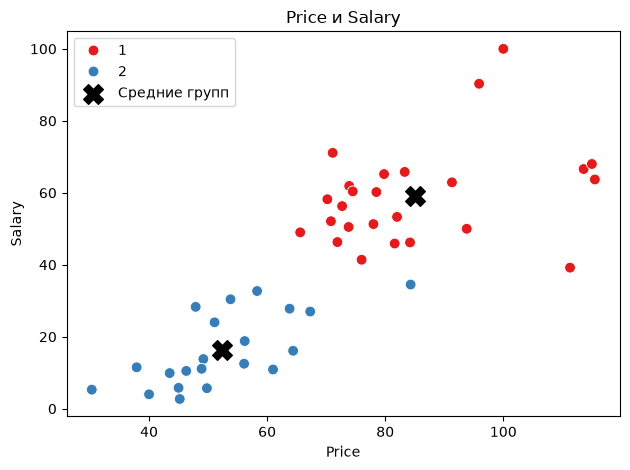

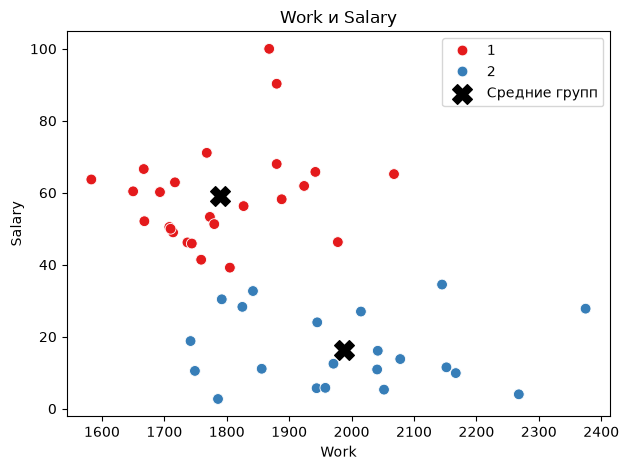

In [26]:
plot_clusters(data, "Price", "Salary")
plot_clusters(data, "Work", "Salary")